# COMET (new method) vs. CellOracle on Paul et al. 2015 data

Evaluates the new COMET pipeline, where each cell's GRN is `A_base + sum_d mix_weights[d] * A_dict[d]`
(a shared base plus a per-cell weighted sum of `D` learned modules), against the CellOracle reference
built in `celloracle_reference.ipynb`. Same metrics as `compare_to_celloracle.ipynb`
(per-TF top-K Jaccard, per-TF union-support Spearman), reported here in both signed and unsigned form.

Kernel: `decipher-env`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import os

COMET_BASE = "/home/elicanter/paul2015_outputs_test_newmethod"
CO_REF = "/home/elicanter/datasets/paul2015data/celloracle_reference"
EPS = 1e-6
TOP_FRAC = 0.10

# ---- COMET outputs ----
# new method: population/global GRN is saved directly as A_learned = A_base + mean-weighted A_dict.
# per-cell GRN = A_base + sum_d mix_weights[cell, d] * A_dict[d]  (see training_loop.py effective_A)
mix_weights = np.load(f"{COMET_BASE}/mix_weights.npy")   # (n_cells, D)
A_dict      = np.load(f"{COMET_BASE}/A_dict.npy")        # (D, G, T) residual modules
A_base      = np.load(f"{COMET_BASE}/A_base.npy")        # (G, T) shared base
A_learned   = np.load(f"{COMET_BASE}/A_learned.npy")     # (G, T) population GRN
A_genes     = np.load(f"{COMET_BASE}/A_genes.npy", allow_pickle=True).astype(str)
A_tfs       = np.load(f"{COMET_BASE}/A_tfs.npy", allow_pickle=True).astype(str)

n_cells, D = mix_weights.shape
G, T = len(A_genes), len(A_tfs)
print(f"COMET: {n_cells} cells, D={D} modules, G={G} genes, T={T} TFs")

# ---- CellOracle reference ----
cell_meta = pd.read_csv(f"{CO_REF}/cell_metadata.csv", index_col=0)   # obs-order cell metadata
co_genes_all = np.load(f"{CO_REF}/base_grn_genes.npy", allow_pickle=True).astype(str)
co_tfs_all   = np.load(f"{CO_REF}/base_grn_tfs.npy", allow_pickle=True).astype(str)

assert len(cell_meta) == n_cells, "cell count mismatch -- positional cell-order alignment breaks"

cluster_names = sorted(f.replace(".csv", "") for f in os.listdir(f"{CO_REF}/edges_by_cluster"))
edges_by_cluster = {cl: pd.read_csv(f"{CO_REF}/edges_by_cluster/{cl}.csv") for cl in cluster_names}
print(f"CellOracle clusters with a fitted GRN: {cluster_names}")

COMET: 2671 cells, D=4 modules, G=1850 genes, T=90 TFs
CellOracle clusters with a fitted GRN: ['10GMP', '12Baso', '13Baso', '14Mo', '15Mo', '16Neu', '17Neu', '1Ery', '2Ery', '3Ery', '4Ery', '5Ery', '6Ery', '7MEP', '8Mk', '9GMP']


## Align gene/TF universes

Restrict COMET's `A_genes`/`A_tfs` and CellOracle's base-GRN universe to their intersection, and
subset all COMET GRN arrays to that shared, identically-ordered index. Cell order is checked above
(same count, same underlying dataset/pipeline as `compare_to_celloracle.ipynb`).

In [2]:
common_genes = np.intersect1d(A_genes, co_genes_all)
common_tfs = np.intersect1d(A_tfs, co_tfs_all)
print(f"Shared genes: {len(common_genes)}/{len(A_genes)} COMET, {len(co_genes_all)} CO")
print(f"Shared TFs:   {len(common_tfs)}/{len(A_tfs)} COMET, {len(co_tfs_all)} CO")

g_idx = pd.Index(A_genes).get_indexer(common_genes)
t_idx = pd.Index(A_tfs).get_indexer(common_tfs)
A_dict    = A_dict[:, g_idx][:, :, t_idx]
A_base    = A_base[g_idx][:, t_idx]
A_learned = A_learned[g_idx][:, t_idx]
A_genes, A_tfs = common_genes, common_tfs
G, T = len(A_genes), len(A_tfs)

gene_pos = {g: i for i, g in enumerate(A_genes)}
tf_pos   = {t: i for i, t in enumerate(A_tfs)}

def edges_to_matrix(df, value_col="coef_mean"):
    """Long CellOracle edge table -> dense signed (G, T) matrix on the shared universe."""
    mat = np.zeros((G, T), dtype=np.float32)
    df = df[df["target"].isin(gene_pos) & df["source"].isin(tf_pos)]
    gi = df["target"].map(gene_pos).to_numpy()
    ti = df["source"].map(tf_pos).to_numpy()
    mat[gi, ti] = df[value_col].to_numpy()
    return mat

co_cluster_mats = {cl: edges_to_matrix(df) for cl, df in edges_by_cluster.items()}

# cell-count-weighted pooled CellOracle GRN -- CellOracle has no native single population GRN
cluster_sizes = cell_meta["paul15_clusters"].value_counts()
w = np.array([cluster_sizes.get(cl, 0) for cl in co_cluster_mats])
w = w / w.sum()
co_global = np.tensordot(w, np.stack(list(co_cluster_mats.values())), axes=1)   # (G, T)
print(f"Built {len(co_cluster_mats)} CellOracle cluster GRNs + pooled global GRN, shape {co_global.shape}")

Shared genes: 1848/1850 COMET, 1850 CO
Shared TFs:   89/90 COMET, 90 CO
Built 16 CellOracle cluster GRNs + pooled global GRN, shape (1848, 89)


## Metrics

Per-TF top-K Jaccard and per-TF union-support Spearman, as in `compare_to_celloracle.ipynb`, each
with a **signed** and **unsigned** variant:

- **unsigned**: ranks/correlates by `|weight|` -- do the two methods agree on which edges matter.
- **signed**: also requires the two GRNs to agree on the direction of regulation (activation vs.
  repression) -- Jaccard intersection only counts a hit if `sign` matches; Spearman correlates raw
  signed weights instead of magnitudes.

In [3]:
def per_tf_topk_jaccard(grn1, grn2, top_frac=TOP_FRAC, eps=EPS, signed=False):
    """Per-TF top-K Jaccard between two (G, T) GRNs. Returns a (T,) array."""
    T_ = grn1.shape[1]
    out = np.full(T_, np.nan)
    for t in range(T_):
        x, y = grn1[:, t], grn2[:, t]
        ax, ay = np.abs(x), np.abs(y)
        nz_x, nz_y = np.flatnonzero(ax > eps), np.flatnonzero(ay > eps)
        if len(nz_x) == 0 or len(nz_y) == 0:
            continue
        k = max(1, round(top_frac * len(np.union1d(nz_x, nz_y))))
        kx, ky = min(k, len(nz_x)), min(k, len(nz_y))
        tx = set(nz_x[np.argsort(ax[nz_x])[::-1][:kx]])
        ty = set(nz_y[np.argsort(ay[nz_y])[::-1][:ky]])
        inter = tx & ty
        if signed:
            inter = {g for g in inter if np.sign(x[g]) == np.sign(y[g])}
        u = tx | ty
        if u:
            out[t] = len(inter) / len(u)
    return out


def per_tf_union_spearman(grn1, grn2, eps=EPS, min_support=5, signed=False, return_support=False):
    """Per-TF Spearman rho on union-support genes. Returns a (T,) array
    (optionally also the per-TF union-support size, for diagnosing small-n noise)."""
    T_ = grn1.shape[1]
    out = np.full(T_, np.nan)
    support_n = np.zeros(T_, dtype=int)
    for t in range(T_):
        x, y = grn1[:, t], grn2[:, t]
        support = np.flatnonzero((np.abs(x) > eps) | (np.abs(y) > eps))
        support_n[t] = len(support)
        if len(support) < min_support:
            continue
        xs, ys = (x[support], y[support]) if signed else (np.abs(x[support]), np.abs(y[support]))
        rho, _ = spearmanr(xs, ys)
        if not np.isnan(rho):
            out[t] = rho
    return (out, support_n) if return_support else out


def null_jaccard(grn1, grn2, top_frac=TOP_FRAC, n=5, seed=0):
    """Permutation floor: shuffle grn2's gene axis, destroying gene correspondence."""
    rng = np.random.default_rng(seed)
    vals = [np.nanmean(per_tf_topk_jaccard(grn1, grn2[rng.permutation(grn2.shape[0])], top_frac))
            for _ in range(n)]
    return np.nanmean(vals)

## Population-level comparison

COMET's global GRN (`A_learned`, saved directly by training) vs. the pooled CellOracle GRN.

In [4]:
jacc_u = np.nanmean(per_tf_topk_jaccard(A_learned, co_global, signed=False))
jacc_s = np.nanmean(per_tf_topk_jaccard(A_learned, co_global, signed=True))
jacc_null = null_jaccard(A_learned, co_global)
rho_u = np.nanmean(per_tf_union_spearman(A_learned, co_global, signed=False))
rho_s = np.nanmean(per_tf_union_spearman(A_learned, co_global, signed=True))

print("=== COMET global GRN (A_learned) vs. CellOracle pooled GRN ===")
print(f"Top-{int(TOP_FRAC*100)}% Jaccard    unsigned: {jacc_u:.4f}   signed: {jacc_s:.4f}   "
      f"(permutation null: {jacc_null:.4f}, {jacc_u/jacc_null:.2f}x)")
print(f"Union Spearman rho   unsigned: {rho_u:.4f}   signed: {rho_s:.4f}")

=== COMET global GRN (A_learned) vs. CellOracle pooled GRN ===
Top-10% Jaccard    unsigned: 0.2271   signed: 0.1420   (permutation null: 0.0278, 8.16x)
Union Spearman rho   unsigned: 0.3501   signed: 0.1024


## How reliable is each TF's agreement score? (support-size check)

`per_tf_union_spearman` only sees the genes either method thinks are candidates for a TF (its
"support"). A TF with few candidate targets gets its rho estimated from very few points, which is
noisy in *both* directions -- that's expected and not a metric flaw. What would be a red flag is a
strong TF (big support) still landing near zero, which points to genuine disagreement rather than
sampling noise. Plotting rho against support size separates the two.

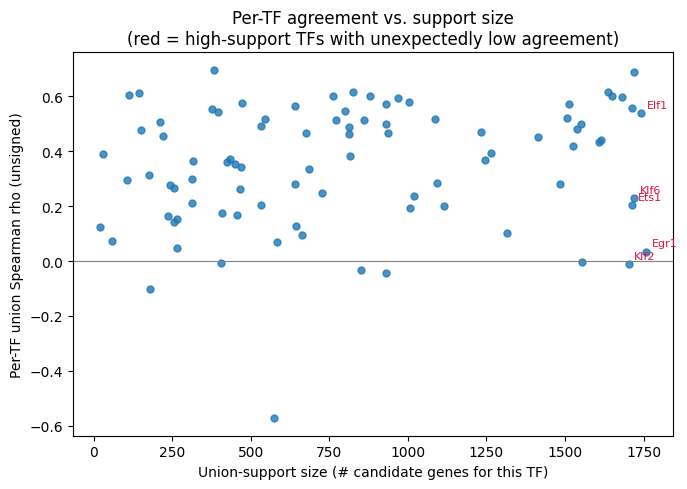

corr(support size, rho) = 0.189  (p=0.076) -- weak/marginal means the hub-score trend seen in the plot below is not simply large-n bias


In [5]:
tf_rho_signed, tf_support = per_tf_union_spearman(A_learned, co_global, signed=True, return_support=True)
tf_rho_unsigned = per_tf_union_spearman(A_learned, co_global, signed=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(tf_support, tf_rho_unsigned, s=25, alpha=0.8)
ax.axhline(0, color="grey", lw=0.8)
low_rho_big_n = np.argsort(tf_support)[::-1]
low_rho_big_n = [i for i in low_rho_big_n if not np.isnan(tf_rho_unsigned[i])][:8]
low_rho_big_n = sorted(low_rho_big_n, key=lambda i: tf_rho_unsigned[i])[:5]
for i in low_rho_big_n:
    ax.annotate(A_tfs[i], (tf_support[i], tf_rho_unsigned[i]), fontsize=8,
                xytext=(4, 4), textcoords="offset points", color="crimson")
ax.set_xlabel("Union-support size (# candidate genes for this TF)")
ax.set_ylabel("Per-TF union Spearman rho (unsigned)")
ax.set_title("Per-TF agreement vs. support size\n(red = high-support TFs with unexpectedly low agreement)")
plt.tight_layout()
plt.show()

rho_supp_corr, rho_supp_p = spearmanr(tf_support, tf_rho_unsigned, nan_policy="omit")
print(f"corr(support size, rho) = {rho_supp_corr:.3f}  (p={rho_supp_p:.3f}) -- "
      "weak/marginal means the hub-score trend seen in the plot below is not simply large-n bias")

## Cell-specific GRNs vs. their matching CellOracle cluster GRN

Each cell's GRN is `A_base + sum_d mix_weights[cell, d] * A_dict[d]` (the exact quantity the model
uses internally, e.g. in `GRNDictionary.effective_A` / `production_from_lead`). For a sample of
cells, score each cell's GRN against every CellOracle cluster GRN, z-normalize each cluster's score
column (removes cluster size/sparsity bias), and take the best match. Compare against the cell's true
`paul15_clusters` label.

Two scoring functions are compared head-to-head -- top-K Jaccard (set overlap of the strongest edges)
and union-support Spearman (rank agreement over all candidate edges) -- to check whether the
threshold-based Jaccard is actually the better choice here, or just the default carried over from the
population-level comparison. Spearman needs a per-(cell, cluster, TF) rank correlation, which is much
slower than Jaccard's precomputed-order lookup, so this section uses a smaller cell sample than a
Jaccard-only pass could support.

In [6]:
true_labels = cell_meta["paul15_clusters"].to_numpy()  # positional, same order as COMET arrays

N_SAMPLE, N_SHUFFLE, SEED = 600, 200, 0
eligible = np.flatnonzero(np.isin(true_labels, cluster_names))
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(eligible, size=min(N_SAMPLE, len(eligible)), replace=False)
print(f"Scoring {len(sample_idx)} cells against {len(cluster_names)} CellOracle cluster GRNs")

# ---- Jaccard scorer (precomputed rank order per cluster/TF) ----
def precompute_orders(grn_abs, eps=EPS):
    orders, mask = [], np.zeros((T, G), dtype=bool)
    for t in range(T):
        x = grn_abs[:, t]
        nz = np.flatnonzero(x > eps)
        orders.append(nz[np.argsort(x[nz])[::-1]])
        mask[t, nz] = True
    return orders, mask

cl_orders, cl_mask, cl_abs = {}, {}, {}
for cl, mat in co_cluster_mats.items():
    cl_orders[cl], cl_mask[cl] = precompute_orders(np.abs(mat))
    cl_abs[cl] = np.abs(mat)

def mean_jaccard_to_cluster(cell_orders, cl, top_frac=TOP_FRAC):
    j = []
    for t in range(T):
        ox, oy = cell_orders[t], cl_orders[cl][t]
        if ox.size == 0 or oy.size == 0:
            continue
        overlap_nz = cl_mask[cl][t][ox].sum()
        union_nz = ox.size + oy.size - overlap_nz
        k = max(1, round(top_frac * union_nz))
        kx, ky = min(k, ox.size), min(k, oy.size)
        inter = np.intersect1d(ox[:kx], oy[:ky], assume_unique=True).size
        j.append(inter / (kx + ky - inter))
    return np.mean(j) if j else np.nan

# ---- Spearman scorer (rank correlation over union support, no scipy per-call overhead) ----
def fast_rank(x):
    order = np.argsort(x)
    ranks = np.empty(len(x))
    ranks[order] = np.arange(len(x))
    return ranks

def mean_spearman_to_cluster(cell_grn_abs, cl, eps=EPS, min_support=5):
    rhos = []
    for t in range(T):
        x, y = cell_grn_abs[:, t], cl_abs[cl][:, t]
        support = np.flatnonzero((x > eps) | (y > eps))
        if len(support) < min_support:
            continue
        rx, ry = fast_rank(x[support]), fast_rank(y[support])
        if rx.std() == 0 or ry.std() == 0:
            continue
        rhos.append(np.corrcoef(rx, ry)[0, 1])
    return np.mean(rhos) if rhos else np.nan

assigned, J_rows, S_rows = [], [], []
for i in sample_idx:
    cell_grn = np.abs(A_base + np.einsum("d,dgt->gt", mix_weights[i], A_dict))
    cell_orders, _ = precompute_orders(cell_grn)
    J_rows.append([mean_jaccard_to_cluster(cell_orders, cl) for cl in cluster_names])
    S_rows.append([mean_spearman_to_cluster(cell_grn, cl) for cl in cluster_names])
    assigned.append(true_labels[i])

assigned = np.array(assigned)
J, S = np.array(J_rows), np.array(S_rows)

def score_matching(scores, name):
    Z = (scores - np.nanmean(scores, axis=0, keepdims=True)) / np.nanstd(scores, axis=0, keepdims=True)
    Z_filled = np.where(np.isnan(Z), -np.inf, Z)
    predicted = np.array(cluster_names)[Z_filled.argmax(1)]
    acc = (predicted == assigned).mean()
    shuffle_acc = np.array([(predicted == rng.permutation(assigned)).mean() for _ in range(N_SHUFFLE)])
    own_idx = np.array([cluster_names.index(a) for a in assigned])
    own_z = Z[np.arange(len(Z)), own_idx]
    ranks = (Z > own_z[:, None]).sum(1) + 1
    print(f"{name:10s}  acc={acc:.3f}  shuffle={shuffle_acc.mean():.3f}+/-{shuffle_acc.std():.3f}  "
          f"mean_rank={ranks.mean():.2f}/{len(cluster_names)}  top3={ (ranks<=3).mean():.3f}")
    return predicted, acc, shuffle_acc, ranks

print(f"(nominal chance = 1/{len(cluster_names)} = {1/len(cluster_names):.3f}, "
      f"random rank = {(len(cluster_names)+1)/2:.1f})")
predicted_j, acc_j, shuffle_j, ranks_j = score_matching(J, "Jaccard")
predicted_s, acc_s, shuffle_s, ranks_s = score_matching(S, "Spearman")

Scoring 600 cells against 16 CellOracle cluster GRNs


(nominal chance = 1/16 = 0.062, random rank = 8.5)
Jaccard     acc=0.212  shuffle=0.070+/-0.010  mean_rank=3.02/16  top3=0.660
Spearman    acc=0.262  shuffle=0.063+/-0.009  mean_rank=4.13/16  top3=0.517


Jaccard and Spearman answer slightly different questions -- Jaccard asks "do the strongest few
edges match", Spearman asks "does the whole ranking agree" -- and the accuracy/rank numbers above show
which one actually resolves cell type better on this data, rather than assuming the population-level
choice carries over. The rest of this section (confusion matrix, rank histogram, per-cluster table)
uses the Jaccard assignment, which is what the previous version of this notebook used, but that's a
one-line swap to `predicted_s` if the cell above shows Spearman wins.

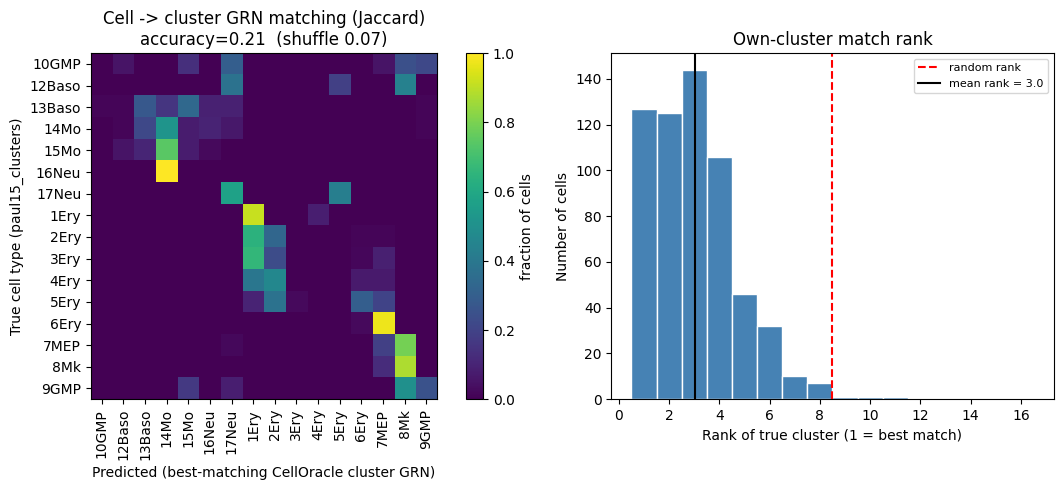

In [7]:
predicted, ranks = predicted_j, ranks_j

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.3, 1]})

conf = pd.crosstab(pd.Series(assigned, name="true"), pd.Series(predicted, name="predicted"))
conf = conf.reindex(index=cluster_names, columns=cluster_names, fill_value=0)
conf_norm = conf.div(conf.sum(axis=1).replace(0, np.nan), axis=0)
im = ax1.imshow(conf_norm.values, vmin=0, vmax=1, cmap="viridis")
ax1.set_xticks(range(len(cluster_names))); ax1.set_xticklabels(cluster_names, rotation=90)
ax1.set_yticks(range(len(cluster_names))); ax1.set_yticklabels(cluster_names)
ax1.set_xlabel("Predicted (best-matching CellOracle cluster GRN)")
ax1.set_ylabel("True cell type (paul15_clusters)")
ax1.set_title(f"Cell -> cluster GRN matching (Jaccard)\naccuracy={acc_j:.2f}  (shuffle {shuffle_j.mean():.2f})")
fig.colorbar(im, ax=ax1, label="fraction of cells", fraction=0.046)

ax2.hist(ranks, bins=np.arange(1, len(cluster_names) + 2) - 0.5, color="steelblue", edgecolor="white")
ax2.axvline((len(cluster_names) + 1) / 2, color="red", ls="--", label="random rank")
ax2.axvline(ranks.mean(), color="black", ls="-", label=f"mean rank = {ranks.mean():.1f}")
ax2.set_xlabel("Rank of true cluster (1 = best match)")
ax2.set_ylabel("Number of cells")
ax2.set_title("Own-cluster match rank")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Is poor matching a model problem or a reference problem?

Some CellOracle clusters are themselves barely distinguishable from a neighboring cluster (e.g.
adjacent points along the erythroid or myeloid trajectories) -- no method can cleanly separate cells
whose *ground truth* GRNs are 30-40% similar. The table below puts each cluster's matching accuracy
next to its size and its most similar other CellOracle cluster, so a low recall number can be read as
"inherently confusable" vs. "COMET actually missed this".

Note: a cluster's GRN vs. itself is trivially 1.0 -- not meaningful, so the diagonal is masked in
the plot and excluded when looking up each cluster's "most similar" match below (otherwise every row
would just point at itself).

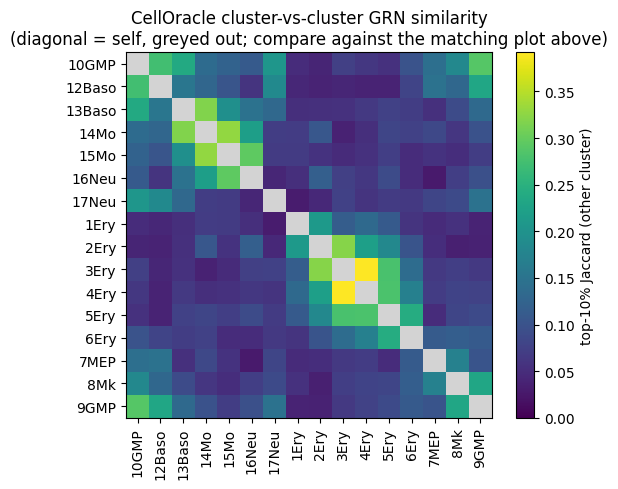

cluster  n_cells_total  n_sampled  recall@1  recall@top3 most_similar_OTHER_cluster  similarity_to_that_cluster
  10GMP            153         37      0.00         0.38                       9GMP                        0.29
 12Baso             69         16      0.00         0.38                      10GMP                        0.27
 13Baso            300         65      0.28         0.74                       14Mo                        0.32
   14Mo            373         79      0.52         0.78                       15Mo                        0.33
   15Mo            186         39      0.08         0.62                       14Mo                        0.33
  16Neu            164         38      0.00         0.21                       15Mo                        0.30
  17Neu             22          7      0.57         0.86                      10GMP                        0.21
   1Ery             43         12      0.92         1.00                       2Ery                     

In [8]:
# CellOracle cluster-vs-cluster GRN similarity (top-K Jaccard, same metric as everything else)
# Self-vs-self is trivially 1.0 (not shown -- masked below); what matters here is how similar
# DIFFERENT clusters' GRNs are to each other, since that sets a ceiling on how well any method
# (COMET included) can tell those two cell types apart from their GRN alone.
K = len(cluster_names)
co_sim = np.eye(K)
for i in range(K):
    for j in range(i + 1, K):
        v = np.nanmean(per_tf_topk_jaccard(co_cluster_mats[cluster_names[i]], co_cluster_mats[cluster_names[j]]))
        co_sim[i, j] = co_sim[j, i] = v

co_sim_plot = co_sim.copy()
np.fill_diagonal(co_sim_plot, np.nan)   # mask self-comparisons so they can't be misread as data

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.cm.viridis.copy(); cmap.set_bad("lightgrey")
im = ax.imshow(co_sim_plot, vmin=0, vmax=np.nanmax(co_sim_plot), cmap=cmap)
ax.set_xticks(range(K)); ax.set_xticklabels(cluster_names, rotation=90)
ax.set_yticks(range(K)); ax.set_yticklabels(cluster_names)
ax.set_title("CellOracle cluster-vs-cluster GRN similarity\n(diagonal = self, greyed out; compare against the matching plot above)")
fig.colorbar(im, ax=ax, label="top-10% Jaccard (other cluster)", fraction=0.046)
plt.tight_layout()
plt.show()

# per-cluster: best match EXCLUDING itself (self is trivially 1.0 and uninformative)
rows = []
for i, cl in enumerate(cluster_names):
    row = co_sim[i].copy(); row[i] = -1
    nn = row.argmax()
    sel = assigned == cl
    recall = (predicted[sel] == cl).mean() if sel.sum() else np.nan
    top3 = (ranks[sel] <= 3).mean() if sel.sum() else np.nan
    rows.append((cl, cluster_sizes.get(cl, 0), sel.sum(), recall, top3,
                 cluster_names[nn], row[nn]))

tbl = pd.DataFrame(rows, columns=["cluster", "n_cells_total", "n_sampled",
                                   "recall@1", "recall@top3",
                                   "most_similar_OTHER_cluster", "similarity_to_that_cluster"])
pd.set_option("display.float_format", lambda v: f"{v:.2f}")
print(tbl.to_string(index=False))

## Hub-TF agreement

Simple hub score per TF (sum of `|weight|` across genes), COMET vs. CellOracle, each point colored by
that TF's per-TF top-K Jaccard (left) or per-TF union Spearman (right) -- same style as
`analysis_scratch/analysis7.ipynb`.

In [1]:
hub_comet = np.abs(A_learned).sum(axis=0)
hub_co = np.abs(co_global).sum(axis=0)
hub_rho, _ = spearmanr(hub_comet, hub_co)

tf_jacc = per_tf_topk_jaccard(A_learned, co_global, signed=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, shading, vmax, label in [(axes[0], tf_jacc, np.nanmax(tf_jacc), f"per-TF top-{int(TOP_FRAC*100)}% Jaccard"),
                                  (axes[1], tf_rho_unsigned, np.nanmax(tf_rho_unsigned), "per-TF union Spearman")]:
    cmap = plt.cm.viridis.copy(); cmap.set_bad("lightgrey")
    sc = ax.scatter(hub_comet, hub_co, c=shading, cmap=cmap, vmin=0, vmax=vmax, s=25, alpha=0.85)
    top10 = np.argsort(hub_comet + hub_co)[-10:]
    for ti in top10:
        ax.annotate(A_tfs[ti], (hub_comet[ti], hub_co[ti]), fontsize=7,
                    xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("COSMOS hub score (sum |weight|)")
    ax.set_ylabel("CellOracle hub score (sum |weight|)")
    ax.set_title(f"{label}\nmean={np.nanmean(shading):.3f}")
    fig.colorbar(sc, ax=ax, label=label)

fig.suptitle(f"Hub-TF agreement, rho={hub_rho:.3f} (n={T} TFs)")
plt.tight_layout()
plt.show()

NameError: name 'np' is not defined